<a href="https://colab.research.google.com/github/aseemanandi-a11y/Galactic_ISM_and_Magnetic_fields/blob/main/01-ISMTurbulence-Model/orginalgalaxy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

0.2411 -4.458 3.878 0.6531 2.345 10.81


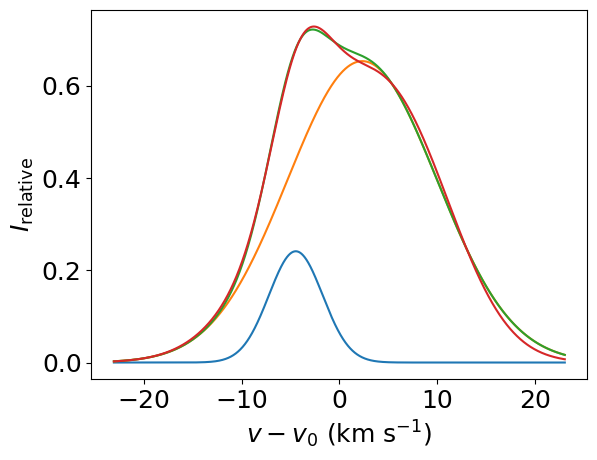

0.3242 8.197 5.446 0.6915 -0.9373 7.609


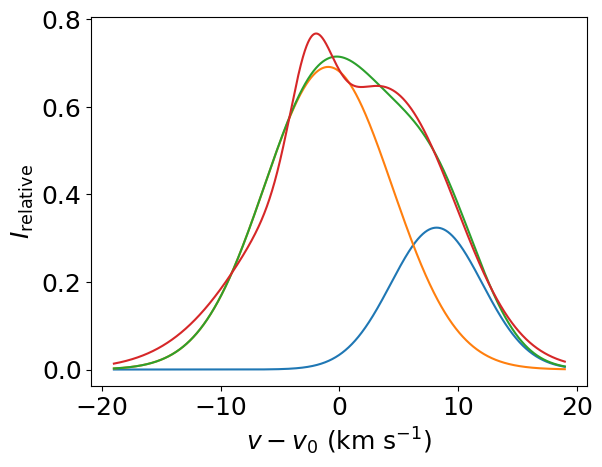

In [ ]:
#galaxy code
import numpy as np
import math
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# meshgrid
Rmax = 16.5
Rmin = 1
Nr = 199
r = np.linspace(Rmin*(1 + 1/Nr), Rmax*(1 - 1/Nr), Nr)
Zmax = 0.7
Zmin = -0.7
Nz = 100
z = np.linspace(Zmin*(1 - 1/Nz), Zmax*(1 - 1/Nz), Nz)
R, Z = np.meshgrid(r, z)
R0 = 8.5  #distance of the sun from the centre of the galaxy
Rstar = 9.8  #radial scale height

#constants
E0 = 10**51  #erg  #energy from one supernova
zeta = 1  #disc halo boundary parameters
cs = 10 #km/s  #speed of sound
NSB = 100  #number of supernovae inside a superbubble
tSB = 100 * (3.1536 * 10**13) #seconds  #lifetime of a superbubble
Ed = 10**51/E0 # this is just 1 no  #dimensionlessE0
pi = math.pi

# scale height calculation
h0 = 0.127  #scale height at R0
h = h0 * np.exp((R - R0) / Rstar)  #scale height
fSB = 0.3      # fraction in superbubbles
fSN = 0.7      # fraction isolated

# calculate <nH1>
X1, Y1 = np.meshgrid(r[0:17], z) # inner galaxy meshgrid
X2, Y2 = np.meshgrid(r[17:103], z) # outer galaxy meshgrid
X3, Y3 = np.meshgrid(r[103:199], z) # far galaxy
nHI1 = 0.092 * (0.7 * np.exp(-(Y1 / (0.127 * np.exp((X1 - 8.5) / 9.8)))**2) +0.19 * np.exp(-(Y1 / (0.318 * np.exp((X1 - 8.5) / 9.8)))**2) +0.11 * np.exp(-np.abs(Y1) / (0.403 * np.exp((X1 - 8.5) / 9.8)))) * (8.5 + 5.2 * (X1 - 2)**2)
nHI2 = 0.092 * (0.7 * np.exp(-(Y2 / (0.127 * np.exp((X2 - 8.5) / 9.8)))**2) +0.19 * np.exp(-(Y2 / (0.318 * np.exp((X2 - 8.5) / 9.8)))**2) +0.11 * np.exp(-np.abs(Y2) / (0.403 * np.exp((X2 - 8.5) / 9.8)))) * (14 * np.exp(-((X2 - 5.5) / 4.78)**2))
nHI3 = 0.092 * (0.7 * np.exp(-(Y3 / (0.127 * np.exp((X3 - 8.5) / 9.8)))**2) +0.19 * np.exp(-(Y3 / (0.318 * np.exp((X3 - 8.5) / 9.8)))**2) +0.11 * np.exp(-np.abs(Y3) / (0.403 * np.exp((X3 - 8.5) / 9.8)))) * 8.2 * np.exp(-((X3 - 9) / 4.5))

#vsn,vsb
X9, Y9 = np.meshgrid(r[0:46], z)
X8, Y8 = np.meshgrid(r[46:199], z)
vSN1 = 50.0 * (3.55 * np.exp(-((X9 - 3.7) / 2.1)**2)) * ( 0.79 * np.exp(-(Y9 / 0.212)**2) +0.21 * np.exp(-(Y9 / 0.636)**2))
vSN2 = 50.0 * (0.79 * np.exp(-(Y8 / 0.212)**2) +0.21 * np.exp(-(Y8 / 0.636)**2)) * np.exp(-((X8**2 - (8.5)**2) / (6.8**2)))
vSN = np.concatenate((vSN1, vSN2), axis=1)  #SN rate density
vSB = vSN / NSB  #SB rate density

# Combine HI
nH1 = np.concatenate((nHI1, nHI2, nHI3), axis=1)  #HI density

# calculate <nH2>
X4, Y4 = np.meshgrid(r[0:33], z)
X5, Y5 = np.meshgrid(r[33:62], z)
X6, Y6 = np.meshgrid(r[62:84], z)
X7, Y7 = np.meshgrid(r[84:199], z)
nH20 = 0.192 * (1.2 * np.exp(((X4 - 2.25) / 1.5)**2) * np.exp(-(Y4 / 0.06)**2))
nH21 = 0.192 * (4.9 * np.exp(-((X5 - 4.8)**2) / 2.4) * np.exp(-(Y5 / 0.06)**2))
nH22 = 0.192 * ((1.51 * np.exp(-(X6 - 7) / 1.65) + 0.1) * np.exp(-(Y6 / 0.06)**2))
nH23 = 0.192 * ((1.51 * np.exp(-(X7 - 7) / 1.65) + 0.1) *np.exp(-(Y7 / (0.06 + 0.019 * (X7 - 7.5)))**2))

# Combine H2
nH2 = np.concatenate((nH20, nH21, nH22, nH23), axis=1)  #HII density

# rho
rho = (14/11)*(1.67*(10**(-24)))*(2*nH2 + nH1)  #overall density
ndim = rho / (1.673532638e-24 * 0.1)  #dimensionless density

# calculate R Rdot (tinj)
tinj = 3.5 * (Ed ** (16/51)) * (ndim ** (-19/51)) * (1 ** (-4/3))  #SN energy injection time
RSN = 0.1 * (Ed**(4/17)) * (ndim**(-19/68)) * (tinj**(1/4))   # kpc  #SN turbulent driving scale
RdotSN = 30.0 * (Ed**(4/17)) * (ndim**(-19/68)) * (tinj**(-3/4))  # km/s  #SN expansion speed at injection

# eta
eta = 0.1 * (ndim**(-0.3))  #SB energy efficiency parameter

# Rsb
tinjSB = 31.0 * (eta / 0.1)**(1/3) * (NSB / 100)**(1/3) * (Ed**(1/3)) * (ndim**(-1/3)) * (1**(-5/3))  #SB energy injection time
RSB = 0.53 * (eta / 0.1)**(1/3) * (NSB / 100)**(1/3) * (Ed**(1/3)) * (ndim**(-1/3)) * (1**(-2/3))   # kpc  #SB turbulent driving scale
RdotSB = 10.0 * (ndim**0)   # km/s  #SB expansion speed at injection

LSB = (eta * NSB * 1e51) / tSB    # erg/s  #mechanical luminosity of SB

# Et,Ethalo
EtSN = (pi*3)*rho*(RSN**2)*(RdotSN**2)*(RSN + zeta*h - abs(Z))*2.939*10**74 # other code did 3*pi instead of pi/3 multiplication #SN energy injected into disc
EthaloSN = (pi*3)*rho*(RSN**2)*(RdotSN**2)*(RSN - zeta*h + abs(Z))*2.939*10**74  #SN energy injected into halo
EtSB = (pi*3)*rho*(RSB**2)*(RdotSB**2)*(RSB + zeta*h - abs(Z))*2.939*10**74  #SB energy injected into disc
EthaloSB = (pi*3)*rho*(RSB**2)*(RdotSB**2)*(RSB - zeta*h + abs(Z))*2.939*10**74  #SB energy injected into halo

# energy correction
# how to fix if both are negative
mask = EthaloSN < 0
EtSN[mask] = EtSN[mask] - EthaloSN[mask]
EthaloSN[mask] = 0
mask = EtSN < 0
EthaloSN[mask] = EthaloSN[mask] - EtSN[mask]
EtSN[mask] = 0
mask = EthaloSB < 0
EtSB[mask] = EtSB[mask] - EthaloSB[mask]
EthaloSB[mask] = 0
mask = EtSB < 0
EthaloSB[mask] = EthaloSB[mask] - EtSB[mask]
EtSB[mask] = 0

# Edotsn Edotsb
EdotSN = vSN * EtSN * (1.079e-78)   # erg cm^-3 s^-1  #SN disc injection rate
EdotSB = (1/30) * vSN * EtSB * (1.079e-78)  #SB disc injection rate
EdothaloSN = vSN * EthaloSN * (1.079e-78)  #SN halo injection rate
EdothaloSB = (1/30) * vSN * EthaloSB * (1.079e-78)  #SB halo injection rate
# Edotdisc Edothalo
Edotdisc = vSN * (fSN * EtSN + fSB * (1/30) * EtSB) * (1.079e-78) #total disc energy injection rate
Edothalo = vSN * (fSN * EthaloSN + fSB * (1/30) * EthaloSB) * (1.079e-78) #total halo energy injection rate
Edot = Edotdisc + Edothalo #total energy injection

# vrms
vrmsdiscSN = (EdotSN * RSN / rho) ** (1/3) * 146  # km s^-1 also other code was missing a factor of 2 #SNdisc turbulence velocity
vrmshaloSN = (EdothaloSN * RSN / rho) ** (1/3) * 146  #SNhalo turbulence velocity
vrmsdiscSB = (EdotSB * RSB / rho) ** (1/3) * 146  #SBdisc turbulence velocity
vrmshaloSB = (EdothaloSB * RSB / rho) ** (1/3) * 146  #SBhalo turbulence velocity

#Integral length scale
ldisc = 0.4 * 0.75 * RSB * ((1 + (RSN / RSB) * (EdotSN / EdotSB)) /(1 + (EdotSN / EdotSB)))  # kpc
lhalo = 0.4 * 0.75 * RSB * ((1 + (RSN / RSB) * (EdothaloSN / EdothaloSB)) /(1 + (EdothaloSN / EdothaloSB)))

# Fix division by zero (NaNs)
mask = np.isnan(lhalo)
lhalo[mask] = ldisc[mask]

# Total integral correlation length scale
l = ldisc + lhalo  # kpc

# Eddy turnover time and total RMS velocity
vrms = (Edotdisc * l / rho) ** (1/3) * 146  # km s^-1 #total turbulence velocity
vout = (Edothalo * l / rho) ** (1/3) * 146 #outflow velocity
vrmsdisc = ((Edotdisc * l) / rho) ** (1/3) * 146  #totaldsic turbulence velocity
tau = l / vrmsdisc * 979  # Myr  #eddy turnover time


# % For i = 53, rfar = 2.41kpc, a1 = 0.391, b1 =-0.479, c1 = 8.066
# % and a2 = 0.3072, b2 = 5.41, c2 = 61.96
# % For i = 53, rfar = 6.41kpc, a1 = 0.2884, b1 =-1.353, c1 = 8.797
# % and a2 = 0.4004, b2 = 2.252, c2 = 26.52
# % For i = 53, rfar = 10.41kpc, a1 = 0.3341, b1 =-5.883, c1 = 9.377
# % and a2 = 0.5105, b2 = 4.308, c2 = 12.93
# % For i = 63, rfar = 1.64kpc, a1 = 0.3476, b1 =-0.3997, c1 = 7.884
# % and a2 = 0.3469, b2 = 1.893, c2 = 41.57
# % For i = 63, rfar = 5.64kpc, a1 = 0.4119, b1 =-2.951, c1 = 11.76
# % and a2 = 0.3127, b2 = 6.784, c2 = 21.59 (note that lower limits of 0.3 set for a1,a2)
# % For i = 63, r = 9.64kpc, a1 = 0.4121, b1 =-5.667, c1 = 7.106
# % and a2 = 0.5642, b2 = 4.54, c2 = 10.37
# % For i = 80, rfar = 1.19kpc, a1 = 0.2411, b1 =-4.458, c1 = 3.878
# % and a2 = 0.6531, b2 = 2.345, c2 = 10.81
# % For i = 80, rfar = 5.19kpc, a1 = 0.3242, b1 = 8.197, c1 = 5.446
# % and a2 = 0.6915, b2 =-0.9373, c2 = 7.609

#update
i = 80
vnvals = [23.519*np.cos(np.deg2rad(i)), 13.842*np.cos(np.deg2rad(i))]
vfvals = [44.2755*np.cos(np.deg2rad(i)), 36.4822*np.cos(np.deg2rad(i))]
vd = 10
fitpars = [

    (0.2411, -4.458, 3.878,
     0.6531, 2.345, 10.81),

    (0.3242, 8.197, 5.446,
     0.6915, -0.9373, 7.609)
]
for j in range(0,2):
  vnear = vnvals[j]
  vfar = vfvals[j]
  vmax = max(vnear, vfar)
  v_v0 = np.linspace( -3*vfar, 3*vfar, 100000)
  I1 = 0.5 * np.exp(-((v_v0**2) / vd**2))
  I2 = 0.25 * np.exp(-((v_v0 - vfar)**2) / vfar**2)
  I3 = 0.25 * np.exp(-((v_v0 + vnear)**2) / vnear**2)

  # #single fit
  # def gaussian(v, A, mu, sigma):
  #   return A * np.exp(-((v - mu)/sigma)**2)

  Itotal = I1+I2+I3   # I2 I3 denominator chk
  # # Fit
  # p0 = [np.max(Itotal), 0, 20]   # initial guesses
  # popt, pcov = curve_fit(gaussian, v_v0, Itotal, p0=p0)

  # A_fit, mu_fit, sigma_fit = popt

  # #Best-fit Gaussian
  # Ifit = gaussian(v_v0, *popt)

  a1,b1,c1,a2,b2,c2 = fitpars[j]
  G1 = a1*np.exp(-((v_v0-b1)/c1)**2)
  G2 = a2*np.exp(-((v_v0-b2)/c2)**2)
  Ifit = G1 + G2

  print(a1,b1,c1,a2,b2,c2)

  # plt.plot(v_v0, I1, label='I1')
  # plt.plot(v_v0, I2, label='I2')
  # plt.plot(v_v0, I3, label='I3')
  plt.plot(v_v0, G1)
  plt.plot(v_v0, G2)
  plt.plot(v_v0, Ifit)
  plt.plot(v_v0, Itotal)

  plt.xlabel(r'$v-v_0$ (km s$^{-1}$)', fontsize=18)
  plt.ylabel(r'$I_{\mathrm{relative}}$', fontsize=18)

  plt.tick_params(labelsize=18)

  plt.show()
